In [4]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
import matplotlib.gridspec as gridspec

In [5]:
import metpy.calc as mpcalc
from metpy.cbook import get_test_data
from metpy.plots import Hodograph, SkewT
from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset
import xarray as xr
from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)
from scipy.stats import bootstrap

In [8]:
var='uh'
center_time=11
length_sim=38
w=2

#exp=['no_urban','10km','20km','30km']

exp=['no_urban_specialcity','green']

upwind_m=np.zeros(len(exp))
upwind_m_std=np.zeros(len(exp))
downwind_m=np.zeros(len(exp))
downwind_m_std=np.zeros(len(exp))

city_m=np.zeros([len(exp),11])
downwind_m=np.zeros([len(exp),11])
upwind_m=np.zeros([len(exp),11])
expval=np.zeros([len(exp),11])

city_m_std=np.zeros(len(exp))
away_m=np.zeros(len(exp))
away_m_std=np.zeros(len(exp))

UH=np.zeros([11,length_sim])

latlon = pd.read_csv("/glade/u/home/fdemartin/dati/citysize/"+var+"_"+exp[0]+".csv") #/glade/u/home/fdemartin/dati/no_urban/"+exp[i]+"_"+"control_max.csv", sep =',')
time_no=latlon['Unnamed: 0'].values
      
for j in range(0,11):
    UH[j,:]=latlon[str(j)].values
    city=UH[j,center_time-w:center_time+w+1]
    city_m[0,j]=np.mean(city)
    upwind=UH[j,center_time-w-4:center_time-w]
    upwind_m[0,j]=np.mean(upwind)
    downwind=UH[j,center_time+w:center_time+w+4]
    downwind_m[0,j]=np.mean(downwind)
    
mean0=np.mean(UH,axis=0)
#print(mean0)

latlon = pd.read_csv("/glade/u/home/fdemartin/dati/citysize/"+var+"_"+exp[1]+".csv") #/glade/u/home/fdemartin/dati/no_urban/"+exp[i]+"_"+"control_max.csv", sep =',')
time_no=latlon['Unnamed: 0'].values
UH=np.zeros([11,length_sim])

for j in range(0,11):
    UH[j,:]=latlon[str(j)].values
    city=UH[j,center_time-w:center_time+w+1]
    city_m[1,j]=np.mean(city)
    upwind=UH[j,center_time-w-4:center_time-w]
    upwind_m[1,j]=np.mean(upwind)
    downwind=UH[j,center_time+w:center_time+w+4]
    downwind_m[1,j]=np.mean(downwind)
#print(UH)    
mean1=np.mean(UH,axis=0)

latlon = pd.read_csv("/glade/u/home/fdemartin/dati/citysize/"+var+"_30km.csv") #/glade/u/home/fdemartin/dati/no_urban/"+exp[i]+"_"+"control_max.csv", sep =',')
time_no=latlon['Unnamed: 0'].values
UH=np.zeros([11,length_sim])

for j in range(0,11):
    UH[j,:]=latlon[str(j)].values
    city=UH[j,center_time-w:center_time+w+1]
    city_m[1,j]=np.mean(city)
    upwind=UH[j,center_time-w-4:center_time-w]
    upwind_m[1,j]=np.mean(upwind)
    downwind=UH[j,center_time+w:center_time+w+4]
    downwind_m[1,j]=np.mean(downwind)
#print(UH)    
mean30km=np.mean(UH,axis=0)

#print(mean1)

0.010553739287636497
The bootstrap confidence interval crosses zero.


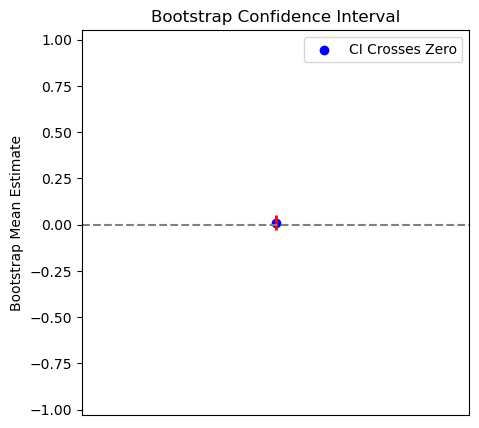

In [432]:
# Compute ensemble differences

ens_diff = upwind_m[1,:]-upwind_m[0,:]

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        
df = pd.DataFrame({"errore": ens_diff})

    # Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')
    
    # Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval
print(mean_m1)
# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 1, high_m1 + 1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()


-0.8059515736319802
The bootstrap confidence interval does NOT cross zero.


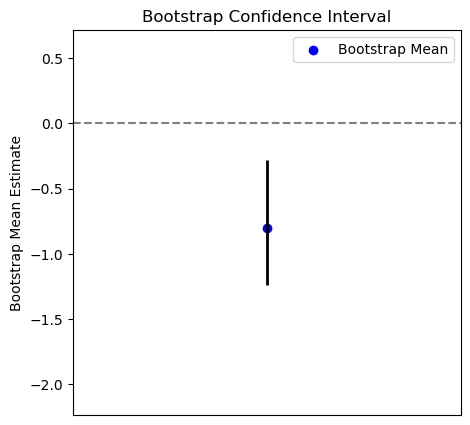

In [433]:
# Compute ensemble differences

ens_diff = city_m[1,:]-city_m[0,:]

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        
df = pd.DataFrame({"errore": ens_diff})

    # Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=1000, method='basic')
    
    # Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval
print(mean_m1)
# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 1, high_m1 + 1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

0.17168040709062057
The bootstrap confidence interval crosses zero.


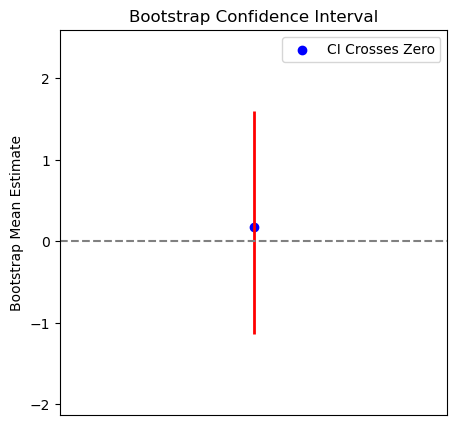

In [434]:
# Compute ensemble differences

ens_diff = downwind_m[1,:]-downwind_m[0,:]

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        
df = pd.DataFrame({"errore": ens_diff})

    # Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')
    
    # Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval
print(mean_m1)
# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 1, high_m1 + 1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

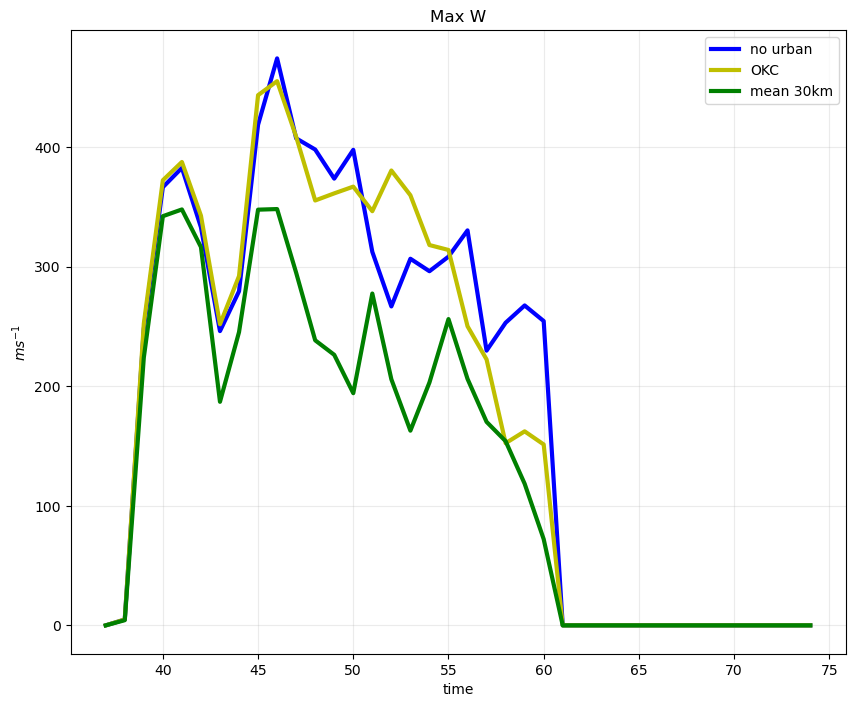

In [9]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,mean0,'b-',linewidth=3, label='no urban')
#ax.errorbar(time, mean1, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,mean1,'y-',linewidth=3, label='OKC')
#ax.errorbar(time, mean1, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,mean30km,'g-',linewidth=3, label='mean 30km')
# ax.errorbar(time, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
#ax.set_ylim(0,50)
#ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)

NameError: name 'UH_mean' is not defined

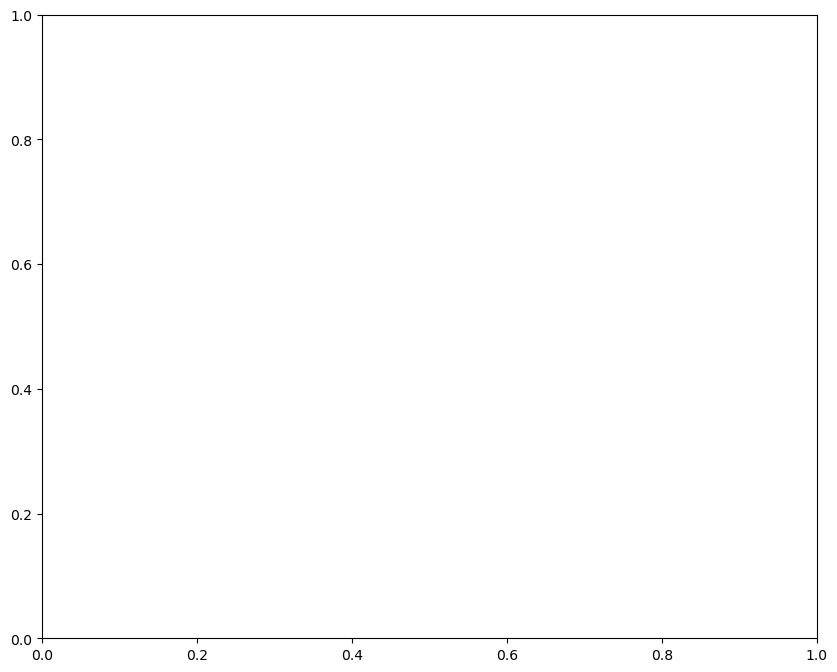

In [436]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
ax.set_ylim(0,50)
ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)

In [ ]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
ax.set_ylim(0,50)
ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)

In [ ]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
ax.set_ylim(0,50)
ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)